<a href="https://colab.research.google.com/github/ppspro/AI.WEATHER/blob/main/Virtual_try_on_Saree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Cell 1 — Runtime check
!nvidia-smi

Sat Mar 21 06:01:19 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# Cell 2 — Clean install the exact stack
%%capture
!pip uninstall -y peft
!pip install -q \
  diffusers==0.30.3 \
  transformers==4.41.2 \
  accelerate==0.31.0 \
  huggingface_hub==0.23.5 \
  safetensors==0.4.3 \
  opencv-python \
  pillow \
  matplotlib \
  git+https://github.com/facebookresearch/segment-anything.git

In [3]:
# Cell 3 — Imports and device
import os
import gc
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from google.colab import files

from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection
from diffusers import StableDiffusionInpaintPipeline
from segment_anything import sam_model_registry, SamPredictor

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32

print("Using device:", DEVICE)
print("Torch version:", torch.__version__)

Using device: cuda
Torch version: 2.10.0+cu128


In [4]:
# Cell 4 — Upload your source image
uploaded = files.upload()
print("Uploaded files:", list(uploaded.keys()))

Saving fat_bg.jpg to fat_bg.jpg
Saving Image_1.png to Image_1.png
Saving Image_2.png to Image_2.png
Saving Image_3.png to Image_3.png
Saving Image_4.png to Image_4.png
Saving Image_5.png to Image_5.png
Saving Image_6.png to Image_6.png
Saving Image_7.png to Image_7.png
Saving Image_8.png to Image_8.png
Saving medium_bg.jpg to medium_bg.jpg
Saving model_image.jpg to model_image.jpg
Saving new_slim.png to new_slim.png
Saving output.png to output.png
Saving saree_image.jpg to saree_image.jpg
Saving slim_bg.jpg to slim_bg.jpg
Uploaded files: ['fat_bg.jpg', 'Image_1.png', 'Image_2.png', 'Image_3.png', 'Image_4.png', 'Image_5.png', 'Image_6.png', 'Image_7.png', 'Image_8.png', 'medium_bg.jpg', 'model_image.jpg', 'new_slim.png', 'output.png', 'saree_image.jpg', 'slim_bg.jpg']


Image size: (1000, 1500)


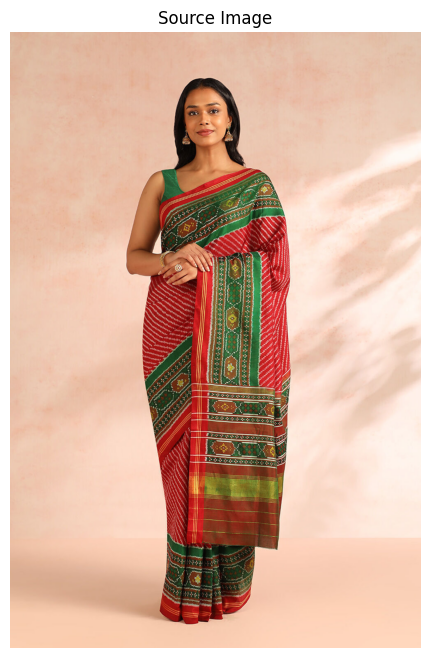

In [5]:
# Cell 5 — Set your image path

# After upload, put your actual filename here.

SOURCE_IMAGE_PATH = "/content/model_image.jpg"   # change only if your filename is different

assert os.path.exists(SOURCE_IMAGE_PATH), f"File not found: {SOURCE_IMAGE_PATH}"

source_pil = Image.open(SOURCE_IMAGE_PATH).convert("RGB")
source_np = np.array(source_pil)

print("Image size:", source_pil.size)

plt.figure(figsize=(6, 8))
plt.imshow(source_pil)
plt.axis("off")
plt.title("Source Image")
plt.show()

In [6]:
# Cell 6 — Download SAM checkpoint

# This uses the official SAM install path and a standard SAM checkpoint.

SAM_CHECKPOINT = "/content/sam_vit_b_01ec64.pth"

if not os.path.exists(SAM_CHECKPOINT):
    !wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth -O /content/sam_vit_b_01ec64.pth

print("SAM checkpoint exists:", os.path.exists(SAM_CHECKPOINT))

SAM checkpoint exists: True


In [7]:
# Cell 7 — Load models

# This uses the Hugging Face Transformers version of Grounding DINO instead of the older repo path. Grounding DINO is officially available in Transformers, and the model repo IDEA-Research/grounding-dino-base is on the Hugging Face Hub. The inpainting model below is the Hub repo documented for SD2 inpainting.

GROUNDING_DINO_MODEL_ID = "IDEA-Research/grounding-dino-base"
INPAINT_MODEL_ID = "sd2-community/stable-diffusion-2-inpainting"

processor = AutoProcessor.from_pretrained(GROUNDING_DINO_MODEL_ID)
grounding_model = AutoModelForZeroShotObjectDetection.from_pretrained(
    GROUNDING_DINO_MODEL_ID
).to(DEVICE)

sam = sam_model_registry["vit_b"](checkpoint=SAM_CHECKPOINT).to(device=DEVICE)
sam_predictor = SamPredictor(sam)

pipe = StableDiffusionInpaintPipeline.from_pretrained(
    INPAINT_MODEL_ID,
    torch_dtype=DTYPE,
)
pipe = pipe.to(DEVICE)

if DEVICE == "cuda":
    pipe.enable_attention_slicing()

print("All models loaded successfully.")

preprocessor_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

...

diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/914 [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

All models loaded successfully.


In [8]:
# Cell 8 — Helper functions
def show_image(img, title="", figsize=(6, 6), cmap=None):
    plt.figure(figsize=figsize)
    plt.imshow(img, cmap=cmap)
    plt.title(title)
    plt.axis("off")
    plt.show()


def detect_best_box(
    image_pil,
    candidate_labels=("saree", "indian saree", "traditional saree", "garment", "dress"),
    box_threshold=0.25,
    text_threshold=0.20
):
    """
    Try multiple prompts and return the single best box.
    """
    best = None
    H, W = image_pil.size[1], image_pil.size[0]

    for label in candidate_labels:
        text_prompt = f"{label}."
        inputs = processor(images=image_pil, text=text_prompt, return_tensors="pt").to(DEVICE)

        with torch.no_grad():
            outputs = grounding_model(**inputs)

        results = processor.post_process_grounded_object_detection(
            outputs,
            inputs.input_ids,
            box_threshold=box_threshold,
            text_threshold=text_threshold,
            target_sizes=[(H, W)]
        )[0]

        boxes = results["boxes"].detach().cpu().numpy() if len(results["boxes"]) > 0 else np.array([])
        scores = results["scores"].detach().cpu().numpy() if len(results["scores"]) > 0 else np.array([])

        if len(boxes) == 0:
            continue

        for box, score in zip(boxes, scores):
            x1, y1, x2, y2 = box
            area = max(1.0, (x2 - x1) * (y2 - y1))
            rank_score = float(score) * float(area)
            item = {
                "label": label,
                "box": box.astype(np.float32),
                "score": float(score),
                "rank_score": rank_score,
            }
            if best is None or item["rank_score"] > best["rank_score"]:
                best = item

    if best is None:
        raise ValueError(
            "No saree-like region was detected. Try a clearer image or change candidate_labels."
        )

    return best


def segment_from_box(image_np, box_xyxy):
    sam_predictor.set_image(image_np)
    masks, scores, _ = sam_predictor.predict(
        box=box_xyxy,
        multimask_output=True
    )
    best_idx = int(np.argmax(scores))
    best_mask = masks[best_idx].astype(np.uint8) * 255
    return best_mask


def refine_preserve_mask(mask_uint8, dilate_kernel=9):
    kernel = np.ones((dilate_kernel, dilate_kernel), np.uint8)
    refined = cv2.morphologyEx(mask_uint8, cv2.MORPH_CLOSE, kernel)
    refined = cv2.dilate(refined, kernel, iterations=1)
    return refined


def make_inpaint_mask_from_preserve_mask(preserve_mask_uint8):
    """
    Diffusers inpainting expects white region = repaint.
    Here we preserve saree and repaint the rest.
    """
    inpaint_mask = 255 - preserve_mask_uint8
    return inpaint_mask


def overlay_box(image_np, box_xyxy, label_text="detected"):
    vis = image_np.copy()
    x1, y1, x2, y2 = [int(v) for v in box_xyxy]
    cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), 3)
    cv2.putText(
        vis,
        label_text,
        (x1, max(20, y1 - 10)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 255, 0),
        2,
        cv2.LINE_AA
    )
    return vis

Best label: indian saree
Best score: 0.8952487707138062
Best box: [ 318.48206  326.30978  685.60913 1440.9926 ]


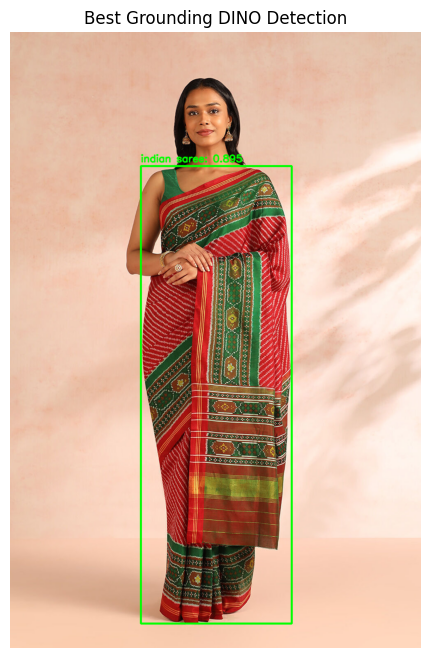

In [9]:
# Cell 9 — Detect saree and make mask
best_detection = detect_best_box(
    source_pil,
    candidate_labels=("saree", "indian saree", "traditional saree", "garment", "dress"),
    box_threshold=0.25,
    text_threshold=0.20
)

best_box = best_detection["box"]
best_label = best_detection["label"]
best_score = best_detection["score"]

print("Best label:", best_label)
print("Best score:", best_score)
print("Best box:", best_box)

boxed = overlay_box(source_np, best_box, f"{best_label}: {best_score:.3f}")
show_image(boxed, "Best Grounding DINO Detection", figsize=(6, 8))

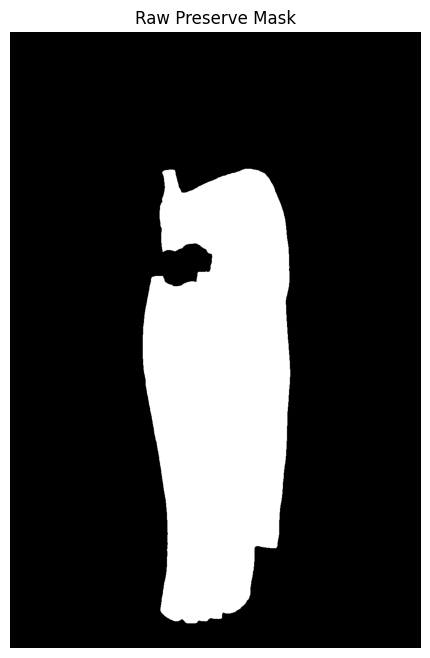

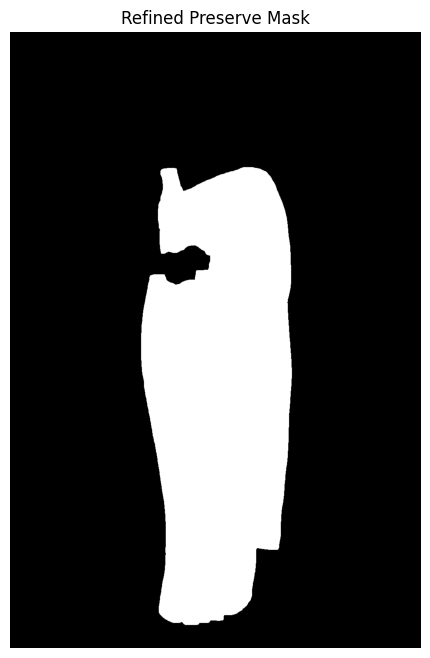

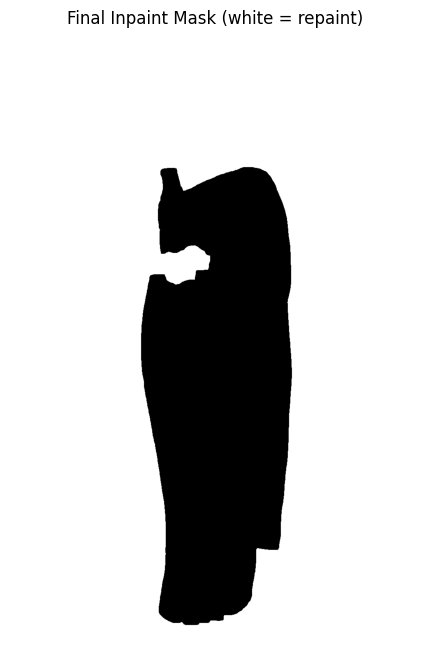

In [10]:
# Cell 10 — Segment the detected region with SAM

# This uses the SAM predictor to turn the bounding box into a pixel-perfect mask.
raw_preserve_mask = segment_from_box(source_np, best_box)
preserve_mask = refine_preserve_mask(raw_preserve_mask, dilate_kernel=9)
inpaint_mask = make_inpaint_mask_from_preserve_mask(preserve_mask)

show_image(raw_preserve_mask, "Raw Preserve Mask", figsize=(6, 8), cmap="gray")
show_image(preserve_mask, "Refined Preserve Mask", figsize=(6, 8), cmap="gray")
show_image(inpaint_mask, "Final Inpaint Mask (white = repaint)", figsize=(6, 8), cmap="gray")

In [11]:
# Cell 11 — Define inpainting parameters

PROMPT = "a woman in a beautiful garden, highly detailed, 8k, cinematic lighting"
NEGATIVE_PROMPT = "low quality, bad anatomy, blurry, distorted, low resolution, face mask, glasses"

print(f"Prompt: {PROMPT}")
print(f"Negative Prompt: {NEGATIVE_PROMPT}")

Prompt: a woman in a beautiful garden, highly detailed, 8k, cinematic lighting
Negative Prompt: low quality, bad anatomy, blurry, distorted, low resolution, face mask, glasses


  0%|          | 0/50 [00:00<?, ?it/s]

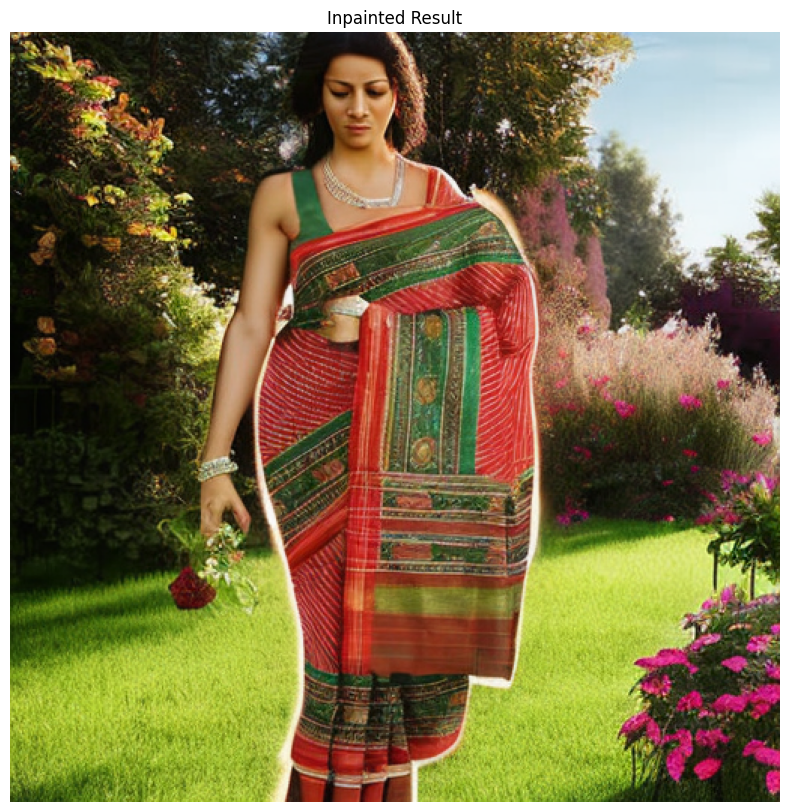

In [12]:
# Cell 12 — Run Inpainting

generated_image = pipe(
    prompt=PROMPT,
    negative_prompt=NEGATIVE_PROMPT,
    image=Image.fromarray(source_np),
    mask_image=Image.fromarray(inpaint_mask),
    num_inference_steps=50,
    guidance_scale=7.5
).images[0]

plt.figure(figsize=(10, 10))
plt.imshow(generated_image)
plt.title("Inpainted Result")
plt.axis("off")
plt.show()

generated_image.save("output_result.png")

In [13]:
# Cell 13 — Download the final result
from google.colab import files

if os.path.exists("output_result.png"):
    files.download("output_result.png")
else:
    print("Output file not found.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>